Notes for Exploratory Data Analysis

Learning outcomes:

*   Define the purpose of Exploratory Data Analysis (EDA) in the data science pipeline
*   Perform structural data inspection and cleaning using Pandas.
*   Analyze univariate distributions using numerical summaries and visualizations
*   Evaluate bivariate and multivariate relationships using correlation metrics, cross-tabulations, and scatter/box plots.
*   Identify, interpret, and handle missing values and outliers systematically.



**Raw Dataset ➔ Structural Inspection ➔ Data Cleaning ➔ Univariate Analysis ➔ Bivariate/Multivariate Analysis ➔ Insights/Hypotheses**

> Add blockquote



*   Dimension & Types: How big is the data? What are the data types (nominal, ordinal, interval, ratio)?

*   Missingness & Duplicates: Where are the gaps, and how are missing values coded?

*   Distribution & Central Tendency: Where is the center, spread, and skewness of each variable?

*   Relationships: How do variables interact with each other?

*   Anomalies: Are there extreme values, and are they errors or genuine signals?

Structural inspection: Before visualizing or running complex statistics, inspect the dataset's skeleton

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Seaborn is a powerful Python library built on top of Matplotlib that is used
# for creating clean, attractive, and informative statistical data visualizations.
# It integrates directly with Pandas DataFrame structures, allowing you to
# create complex plots like heatmaps, violin plots, and regression lines

# Load sample dataset (using seaborn's built-in titanic dataset)
df = sns.load_dataset('titanic')

# 1. Structural Overview
print("Dataset Shape:", df.shape)  # Rows, Columns
print("\n--- Data Types & Non-Null Counts ---")
print(df.info())

# 2. View First/Last Rows
print("\n--- Head ---")
print(df.head(5))

# 3. Check for Duplicate Records
duplicate_count = df.duplicated().sum()
print(f"\nDuplicate Rows: {duplicate_count}")

Dataset Shape: (891, 15)

--- Data Types & Non-Null Counts ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   survived     891 non-null    int64   
 1   pclass       891 non-null    int64   
 2   sex          891 non-null    object  
 3   age          714 non-null    float64 
 4   sibsp        891 non-null    int64   
 5   parch        891 non-null    int64   
 6   fare         891 non-null    float64 
 7   embarked     889 non-null    object  
 8   class        891 non-null    category
 9   who          891 non-null    object  
 10  adult_male   891 non-null    bool    
 11  deck         203 non-null    category
 12  embark_town  889 non-null    object  
 13  alive        891 non-null    object  
 14  alone        891 non-null    bool    
dtypes: bool(2), category(2), float64(2), int64(4), object(5)
memory usage: 80.7+ KB
None

--- Head -

Nominal: Categorical variables without ordering (e.g., sex, embarked).

Ordinal: Categorical variables with an implicit order (e.g., class: First > Second > Third).

Continuous/Discrete: Numeric values representing counts or measurements (e.g., age, fare, sibsp).

Missing data:
*   Completely at random
*   Missingness depends on observed data
*   Missingness depends directly on the unobserved value (high-income earners omitting their income)

In [ ]:
# Missing Value Breakdown
missing_summary = pd.DataFrame({
    'Missing Count': df.isnull().sum(),
    'Percentage (%)': (df.isnull().sum() / len(df)) * 100
}).sort_values(by='Percentage (%)', ascending=False)

print(missing_summary[missing_summary['Missing Count'] > 0])

             Missing Count  Percentage (%)
deck                   688       77.216611
age                    177       19.865320
embarked                 2        0.224467
embark_town              2        0.224467


Percentage Missing	     & Associated       Strategy

< 5%	Listwise deletion (drop rows)

5% – 40%	Imputation (Mean, Median, Mode, K-NN) Use Median for skewed data; Mode for categorical

More than 40%	Drop column or create is_missing flag (imputation would introduce large artificial variance)

**Univariate Analysis** (individually check mean and variance)

* Mean vs. Median: Large differences signal skewness.

* Standard Deviation & Interquartile Range (IQR): Measure of spread

For continuous categories - observe mean, median and dispersion

       count       mean        std   min      25%      50%   75%       max
age    714.0  29.699118  14.526497  0.42  20.1250  28.0000  38.0   80.0000
fare   891.0  32.204208  49.693429  0.00   7.9104  14.4542  31.0  512.3292
sibsp  891.0   0.523008   1.102743  0.00   0.0000   0.0000   1.0    8.0000
parch  891.0   0.381594   0.806057  0.00   0.0000   0.0000   0.0    6.0000


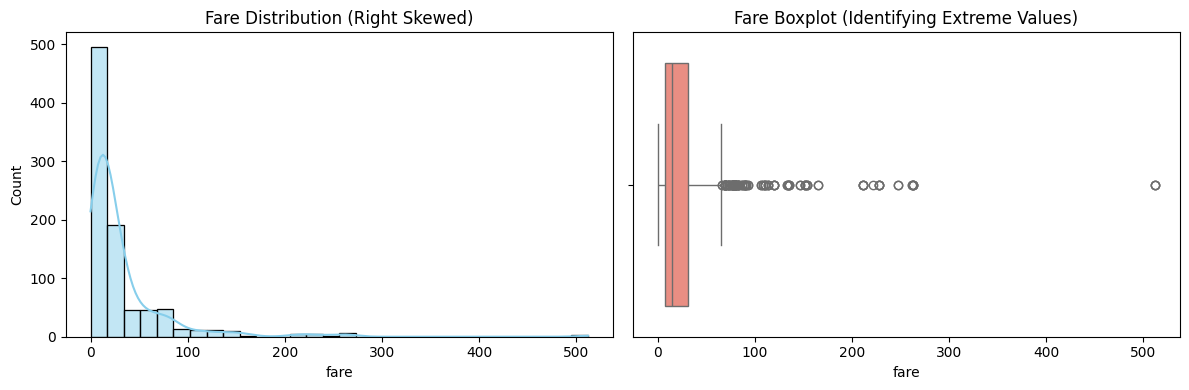

In [ ]:
# Summary statistics for numerical features
print(df[['age', 'fare', 'sibsp', 'parch']].describe().T)

# Visualizing Distribution: Histogram + KDE
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
sns.histplot(df['fare'], kde=True, bins=30, color='skyblue')
plt.title('Fare Distribution (Right Skewed)')

plt.subplot(1, 2, 2)
sns.boxplot(x=df['fare'], color='salmon')
plt.title('Fare Boxplot (Identifying Extreme Values)')

plt.tight_layout()
plt.show()

* $\text{Skewness} = 0$: Symmetric distribution (e.g., Normal Distribution).
* $\text{Skewness} > 0$: Right-skewed (long tail on the right; Mean > Median).
* $\text{Skewness} < 0$: Left-skewed (long tail on the left; Mean < Median).

For discrete categories, examine frequencies and proportions.

        Count  Percentage
class                    
Third     491   55.106622
First     216   24.242424
Second    184   20.650954


/tmp/ipykernel_1816/3326506993.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='class', palette='viridis')


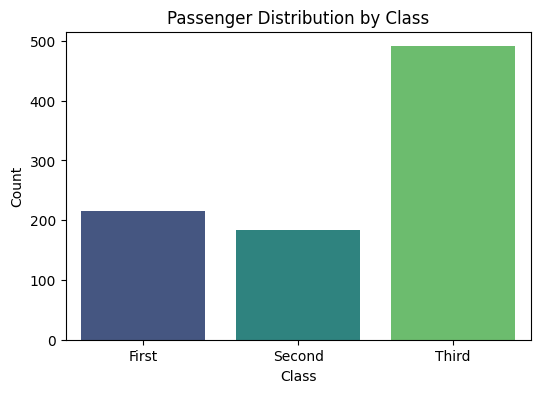

In [ ]:
# Frequency and Relative Frequency
class_counts = df['class'].value_counts()
class_props = df['class'].value_counts(normalize=True) * 100

freq_table = pd.DataFrame({'Count': class_counts, 'Percentage': class_props})
print(freq_table)

# Visualizing Categorical Counts
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x='class', palette='viridis')
plt.title('Passenger Distribution by Class')
plt.xlabel('Class')
plt.ylabel('Count')
plt.show()

# Bivariate and Multivariate Analysis - **Correlations**

Correlation measures the strength and direction of a linear relationship between two quantitative variables. Pearson's correlation coefficient ($r$) ranges from $-1$ to $+1$:$$r = \frac{\sum (x_i - \bar{x})(y_i - \bar{y})}{\sqrt{\sum (x_i - \bar{x})^2 \sum (y_i - \bar{y})^2}}$$

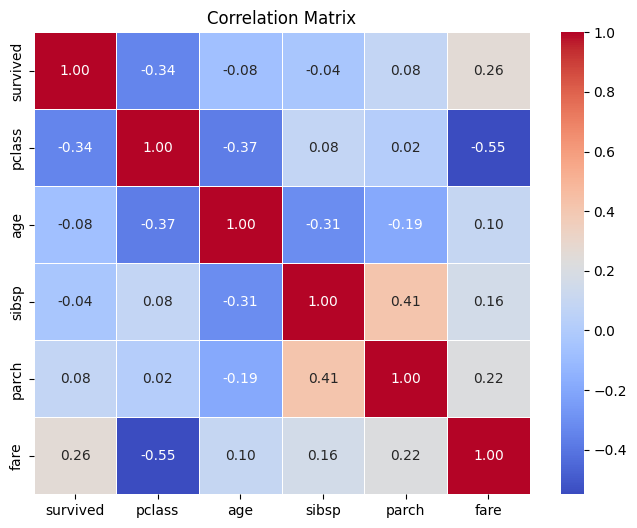

In [ ]:
# Correlation Matrix
num_cols = df.select_dtypes(include=[np.number]).columns
corr_matrix = df[num_cols].corr(method='pearson')

# Heatmap Visualization
plt.figure(figsize=(8, 6))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title('Correlation Matrix')
plt.show()

Correlation does not imply Causation and Pearson's $r$ only captures linear relationships (non-linear relationships may show $r \approx 0$).

**Categorical vs. Continuous: Grouped Aggregations & Box Plots**

/tmp/ipykernel_1816/169039464.py:2: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  age_by_class = df.groupby('class')['age'].agg(['mean', 'median', 'std']).reset_index()


    class       mean  median        std
0   First  38.233441    37.0  14.802856
1  Second  29.877630    29.0  14.001077
2   Third  25.140620    24.0  12.495398


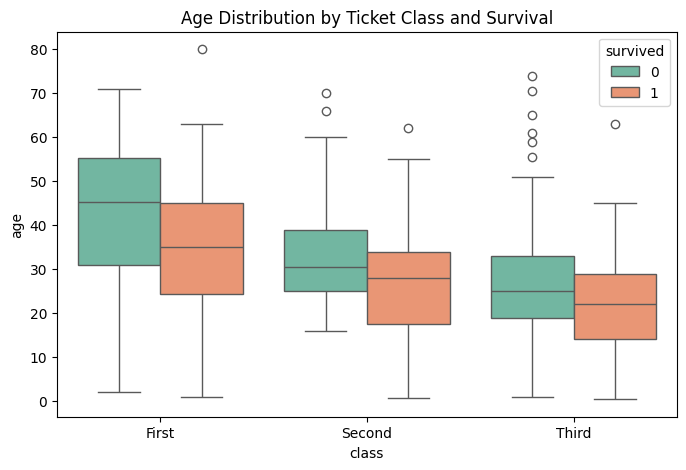

In [ ]:
# Numerical summary grouped by category
age_by_class = df.groupby('class')['age'].agg(['mean', 'median', 'std']).reset_index()
print(age_by_class)

# Visualizing distribution across groups
plt.figure(figsize=(8, 5))
sns.boxplot(x='class', y='age', hue='survived', data=df, palette='Set2')
plt.title('Age Distribution by Ticket Class and Survival')
plt.show()

**Categorical vs. Categorical: Contingency Tables & Stacked Bars**

survived          0          1
class                         
First     37.037037  62.962963
Second    52.717391  47.282609
Third     75.763747  24.236253


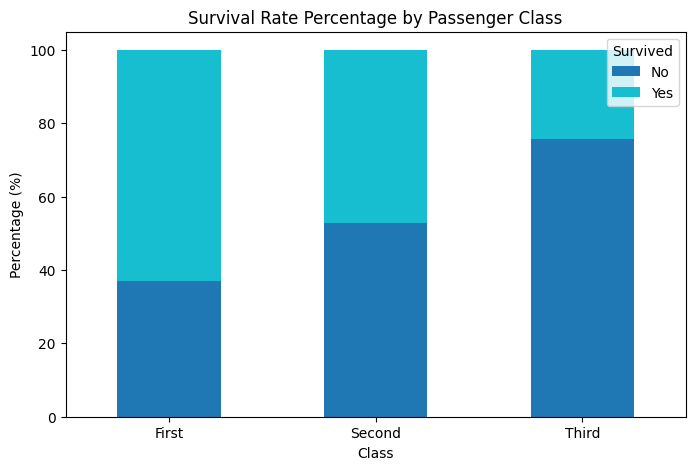

In [ ]:
# Contingency Table (Cross-tabulation)
ct = pd.crosstab(df['class'], df['survived'], normalize='index') * 100
print(ct)

# Stacked Bar Chart
ct.plot(kind='bar', stacked=True, figsize=(8, 5), colormap='tab10')
plt.title('Survival Rate Percentage by Passenger Class')
plt.ylabel('Percentage (%)')
plt.xlabel('Class')
plt.xticks(rotation=0)
plt.legend(title='Survived', labels=['No', 'Yes'])
plt.show()

**Outlier Detection and Treatment**

Method 1: Interquartile Range (IQR) MethodAn observation is considered an outlier if it lies outside:
* $\text{Lower Bound} = Q_1 - 1.5 \times \text{IQR}$

* $\text{Upper Bound} = Q_3 + 1.5 \times \text{IQR}$
where $\text{IQR} = Q_3 - Q_1$.

In [ ]:
def detect_outliers_iqr(data, col):
    Q1 = data[col].quantile(0.25)
    Q3 = data[col].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = data[(data[col] < lower_bound) | (data[col] > upper_bound)]
    print(f"{col} - Q1: {Q1:.2f}, Q3: {Q3:.2f}, IQR: {IQR:.2f}")
    print(f"Lower Bound: {lower_bound:.2f}, Upper Bound: {upper_bound:.2f}")
    print(f"Number of Outliers: {len(outliers)}")
    return lower_bound, upper_bound

lower, upper = detect_outliers_iqr(df, 'fare')

fare - Q1: 7.91, Q3: 31.00, IQR: 23.09
Lower Bound: -26.72, Upper Bound: 65.63
Number of Outliers: 116


Method 2: Z-Score Method (Assumes Normally Distributed Data)

An observation is an outlier if its Z-score falls outside $[-3, 3]$:

$$Z = \frac{X - \mu}{\sigma}$$

In [ ]:
from scipy import stats

df_clean_age = df.dropna(subset=['age']).copy()
df_clean_age['age_zscore'] = stats.zscore(df_clean_age['age'])

outliers_z = df_clean_age[df_clean_age['age_zscore'].abs() > 3]
print(f"Number of Z-score outliers in Age: {len(outliers_z)}")

Number of Z-score outliers in Age: 2


**Handling outliers**

*  Retain: If the outlier represents valid, natural data (e.g., high income in financial modeling).
*  Cap/Winsorize: Replace values above the 99th percentile or below the 1st percentile with those boundary values.
*  Transform: Apply logarithmic ($\ln(x + 1)$) or square-root transformations to reduce right-skewness.
*  Remove: Only if confirmed to be corrupt or erroneous data entry.

Avoid the following:
* Premature cleanup
* Ignoring data types (Roll no.s etc treated as continuous numerical variables)
* Not considering Data Leakage - Computing mean imputation etc efore train-test splits
* Visual misrepresentation: Truncating axis limits on bar plots, poor bin sizes,

**Missing data replacement** (known as imputation) substitutes missing values (NaN, None, or placeholder values like -999) with plausible values based on statistical summaries, group patterns, or machine learning algorithms.

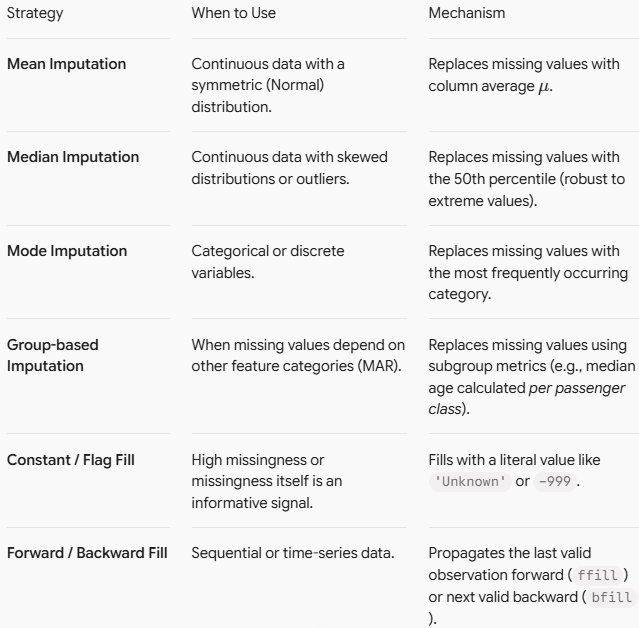

Pandas Commands
* df.fillna(value): Primary method to replace NaN values with a specified constant, dictionary, or calculated statistic.

* df.transform() / df.groupby(): Used to compute group-level statistics (e.g., subgroup medians) and broadcast them across missing rows.

* df.replace(to_replace, value): Used to convert custom non-standard missing flags (e.g., '?', -999, '') into np.nan or concrete values.

* df.interpolate(): Fills NaN values using basic linear or polynomial trend interpolation.

Scikit-Learn Commands:

SimpleImputer(strategy='mean'|'median'|'most_frequent'|'constant'): Transformer class designed for machine learning pipelines to prevent data leakage during train/test splits.

Mode Imputation for Categorical Features (Embarked)

The embarked column has only 2 missing values. Since it is categorical, we fill it with the mode (most common port).

In [ ]:
# 1. Calculate mode
embarked_mode = df['embarked'].mode()[0]
print(f"Most frequent port: {embarked_mode}")

# 2. Fill missing values
df['embarked'] = df['embarked'].fillna(embarked_mode)

# Verify
print("Missing embarked values:", df['embarked'].isnull().sum())

Most frequent port: S
Missing embarked values: 0


Grouped Median Imputation for Numerical Features (age)

Instead of filling age with a global median, calculating the median age grouped by pclass and sex provides a much more accurate estimate.

In [ ]:
# Check median age by Class and Sex
grouped_medians = df.groupby(['pclass', 'sex'])['age'].median()
print("Median Age by Class and Sex:")
print(grouped_medians)

# Apply group-level median imputation using transform()
df['age'] = df.groupby(['pclass', 'sex'])['age'].transform(
    lambda group: group.fillna(group.median())
)

# Verify
print("Missing age values:", df['age'].isnull().sum())

Median Age by Class and Sex:
pclass  sex   
1       female    35.0
        male      40.0
2       female    28.0
        male      30.0
3       female    21.5
        male      25.0
Name: age, dtype: float64
Missing age values: 0


onstant Category Replacement (deck)
The deck column is missing over 70% of its data. Imputing values introduces excessive noise, so we convert missing values to a distinct category called 'Unknown'

In [ ]:
# Because 'deck' is a Pandas Categorical series, first add 'Unknown' to categories
df['deck'] = df['deck'].cat.add_categories('Unknown')

# Fill missing values with 'Unknown'
df['deck'] = df['deck'].fillna('Unknown')

# Verify frequency count including the new category
print(df['deck'].value_counts())

deck
Unknown    688
C           59
B           47
D           33
E           32
A           15
F           13
G            4
Name: count, dtype: int64


Scikit-Learn SimpleImputer (ML Pipeline Style)


When preparing data for machine learning models, use sklearn.impute.SimpleImputer to fit statistics on training data and transform validation/test sets cleanly.

In [ ]:
from sklearn.impute import SimpleImputer

# Reload fresh dataset copy
df_ml = sns.load_dataset('titanic')

# Initialize median imputer for numerical columns
num_imputer = SimpleImputer(strategy='median')

# Fit and transform 'age' and 'fare'
df_ml[['age', 'fare']] = num_imputer.fit_transform(df_ml[['age', 'fare']])

# Initialize mode imputer for categorical columns
cat_imputer = SimpleImputer(strategy='most_frequent')

# Fit and transform 'embarked'
df_ml[['embarked']] = cat_imputer.fit_transform(df_ml[['embarked']])

print("Missing values after SimpleImputer:")
print(df_ml[['age', 'fare', 'embarked']].isnull().sum())

Missing values after SimpleImputer:
age         0
fare        0
embarked    0
dtype: int64


**Exercise:** Penguins dataset

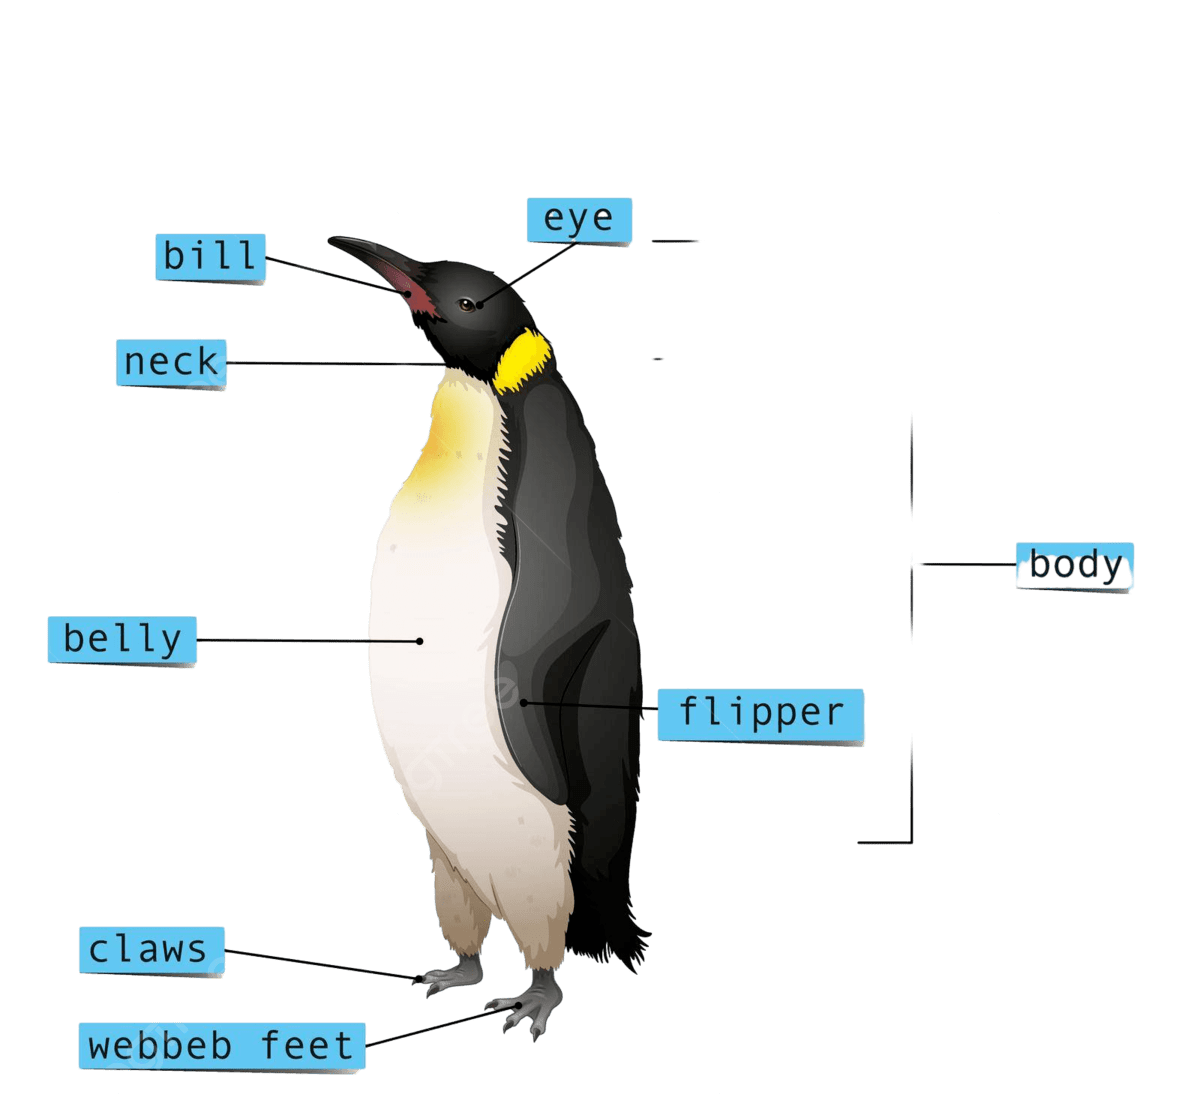

1. Load the penguins dataset via *sns.load_dataset('penguins')*. (this dataset contains width and height of the

2. Find all missing values and decide on an imputation strategy for bill_length_mm vs. sex.

3. Compute the correlation matrix between bill_length_mm, bill_depth_mm, flipper_length_mm, and body_mass_g.

4. Plot a scatter plot of bill_length_mm vs bill_depth_mm. Color the points by species.

5. E.g.: What happens to the direction of correlation between bill length and bill depth when you analyze the dataset globally versus when you split it by species?